# Data Exploration and Preprocessing 

## Data understanding 
working on the bike_types.csv file 

### Load the data 

In [2]:
import pandas as pd
import numpy as np

# Load the data
bike_types = pd.read_csv("../data/raw/bike_types.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

### Infos of the data 

characteristics of bikes,

In [3]:
bike_types.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
bike_types.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     str    
 2   name              91 non-null     str    
 3   description       51 non-null     str    
 4   form_factor       91 non-null     str    
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     str    
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 8.6 KB


valeurs nulles 

In [5]:
bike_types.isna().sum()
bike_types.isna().sum().sum()       # total count
bike_types.isna().mean() * 100

id                   0.000000
vehicle_image       24.793388
name                24.793388
description         57.851240
form_factor         24.793388
rider_capacity      24.793388
propulsion_type     24.793388
max_range           87.603306
battery_capacity    81.818182
dtype: float64

Plage de valeurs :

In [6]:
bike_types.describe()

,id,rider_capacity,max_range,battery_capacity
count,121.000000,91.000000,15.0,22.000000
mean,134.454545,1.230769,60000.0,547.727273
std,77.738450,0.423659,0.0,61.638873
min,0.000000,1.000000,60000.0,500.000000
25%,72.000000,1.000000,60000.0,500.000000
50%,149.000000,1.000000,60000.0,500.000000
75%,201.000000,1.000000,60000.0,600.000000
max,254.000000,2.000000,60000.0,690.000000


max_range est vide à 88 % et vaut toujours 60 000 quand il est renseigné. battery_capacity est vide à 82 % et varie" de 500 à 690. Ces deux colonnes n'apportent presque rien, et c'est pareil pour vehicle_image et description.

Visualiser la distribution :

array([[<Axes: title={'center': 'id'}>,
        <Axes: title={'center': 'rider_capacity'}>],
       [<Axes: title={'center': 'max_range'}>,
        <Axes: title={'center': 'battery_capacity'}>]], dtype=object)

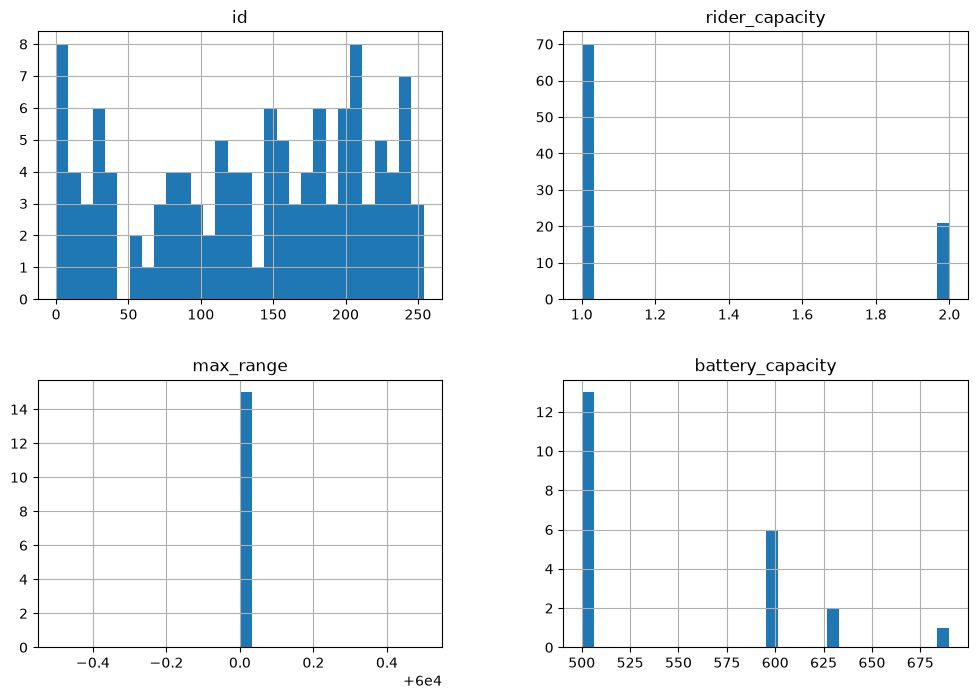

In [7]:
bike_types.hist(figsize=(12, 8), bins=30)


In [8]:
# 1. Lignes vides : à garder, mais marquées "unknown" plutôt que supprimées
#    (1 050 vélos y renvoient, les supprimer ferait perdre leurs trajets)
empty = bike_types.drop(columns="id").isna().all(axis=1)
print(f"{empty.sum()} types vides")

bt = bike_types.copy()
bt[["form_factor", "propulsion_type"]] = bt[["form_factor", "propulsion_type"]].fillna("unknown")

# 2. Garder seulement les colonnes utiles + une variable simple
bt = bt[["id", "name", "form_factor", "propulsion_type", "rider_capacity"]]
bt["is_electric"] = bt["propulsion_type"].map(
    {"electric_assist": 1, "human": 0, "unknown": np.nan})

# 3. Croiser les deux variables principales
pd.crosstab(bt["form_factor"], bt["propulsion_type"])


30 types vides


propulsion_type,electric_assist,human,unknown
form_factor,,,
bicycle,15,56,0
cargo_bicycle,12,7,0
other,0,1,0
unknown,0,0,30


## Data understanding 
working on the bike.csv file 

In [9]:
bikes = pd.read_csv("../data/raw/bikes.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

In [10]:
bikes.head()

,id,bike_type_id,computer_id
0,400481,196,83300002927
1,374044,204,7551171765
2,373778,204,7551140444
3,34749,14,0
4,88359,143,7551052355


In [11]:
bikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 88436 entries, 0 to 88435
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            88436 non-null  int64
 1   bike_type_id  88436 non-null  int64
 2   computer_id   88436 non-null  int64
dtypes: int64(3)
memory usage: 2.0 MB


In [12]:
bikes.isna().sum()
bikes.isna().sum().sum()       # total count
bikes.isna().mean() * 100

id              0.0
bike_type_id    0.0
computer_id     0.0
dtype: float64

In [13]:
bikes.describe()

,id,bike_type_id,computer_id
count,88436.000000,88436.000000,8.843600e+04
mean,287347.736182,130.639739,6.533541e+09
std,262380.844954,68.631175,8.500256e+09
min,2204.000000,0.000000,0.000000e+00
25%,45033.500000,71.000000,7.551012e+09
50%,224069.500000,150.000000,7.551068e+09
75%,485216.500000,196.000000,7.551120e+09
max,998499.000000,254.000000,7.551011e+11


In [14]:
# Doublons
print("id en double :", bikes["id"].duplicated().sum())

id en double : 0


In [15]:
# computer_id = 0 : sans doute "pas d'ordinateur", ou une valeur manquante codée par 0
print("computer_id == 0 :", (bikes["computer_id"] == 0).sum())

computer_id == 0 : 13136


on a 13136 valeurs nulles de computer_id, donc "pas d'ordinateur" pour le bike => il faut remplacer les valeurs nulles pas NaN 

In [16]:
# Doublons de computer_id, en ignorant les 0
non_zero = bikes[bikes["computer_id"] != 0]
print("computer_id en double :", non_zero["computer_id"].duplicated().sum())

computer_id en double : 3023


3023 doublons => des boitiers utilises d'un velo a l'autre 

### Conclusion :
Ici pas de valeurs manquantes, la table est un pont entre les trajets et les caracteristques de velos, il faut faire une fusion avec la table bike_types afin de savoir l'information du trajet est fait avec quel type de velo 

## Data understanding 
working on the trips_small.csv file 

In [17]:
trips = pd.read_csv("../data/raw/trips_small.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

In [18]:
trips.head()


,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [19]:
trips.info()

<class 'pandas.DataFrame'>
RangeIndex: 1161376 entries, 0 to 1161375
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   bike_id           1161376 non-null  int64  
 1   city_id           1161376 non-null  int64  
 2   time_start        1161376 non-null  float64
 3   lon_start         1161376 non-null  float64
 4   lat_start         1161376 non-null  float64
 5   lon_end           1161376 non-null  float64
 6   lat_end           1161376 non-null  float64
 7   station_id_start  1072161 non-null  float64
 8   station_id_end    1039472 non-null  float64
 9   battery_start     168532 non-null   float64
 10  battery_end       168641 non-null   float64
 11  duration          1161376 non-null  float64
 12  distance          1161376 non-null  float64
dtypes: float64(11), int64(2)
memory usage: 115.2 MB


In [20]:
trips.isna().sum()

bike_id                  0
city_id                  0
time_start               0
lon_start                0
lat_start                0
lon_end                  0
lat_end                  0
station_id_start     89215
station_id_end      121904
battery_start       992844
battery_end         992735
duration                 0
distance                 0
dtype: int64

In [21]:
trips.isna().sum().sum()       # total count

np.int64(2196698)

In [22]:
trips.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681836
station_id_end      10.496514
battery_start       85.488593
battery_end         85.479207
duration             0.000000
distance             0.000000
dtype: float64

85.4% de valeurs manquantes de la variable battery_start et 85.5% pour battery_end, c'est peut etre du a l'absence de computer dans la bike a propulsion humaine. ces valeurs sont donc non applicables a ces varibales, expliquant leurs manque

les deux colonnes sont-elles manquantes ensemble ?

In [23]:
start_na = trips["battery_start"].isna()
end_na   = trips["battery_end"].isna()

print("les deux manquants :", (start_na & end_na).mean())
print("seulement start manquant :", (start_na & ~end_na).sum())
print("seulement end manquant :", (~start_na & end_na).sum())

les deux manquants : 0.8547800195630011
seulement start manquant : 123
seulement end manquant : 14


## Data understanding 
working on the cities.csv file 

In [24]:
cities = pd.read_csv("../data/raw/cities.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

In [25]:
cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [26]:
cities.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 12.9 KB


In [27]:
cities.isna().sum()

id                         0
name                       0
lat                        0
lon                        0
timezone                   0
country                    0
return_to_official_only    0
dtype: int64

In [28]:
cities["id"].duplicated().sum()


np.int64(0)

In [29]:
cities[["lat", "lon"]].describe()

,lat,lon
count,267.000000,267.000000
mean,49.067596,12.154192
std,4.155125,7.029840
min,27.815400,-15.518200
25%,47.827850,8.306550
50%,49.898000,13.744600
75%,51.589750,16.831200
max,57.690200,33.453500


Cohérence pays / fuseau horaire

In [30]:
pd.crosstab(cities["country"], cities["timezone"])

timezone,Asia/Istanbul,Atlantic/Canary,Europe/Berlin,Europe/Bratislava,Europe/Brussels,Europe/London,Europe/Riga,Europe/Rome,Europe/Warsaw
country,,,,,,,,,
AT,0,0,24,0,0,0,0,0,0
CH,0,0,0,0,13,0,0,0,0
CY,2,0,0,0,0,0,0,0,0
CZ,0,0,25,0,0,0,0,0,0
DE,0,0,90,0,0,0,0,1,0
ES,0,3,12,0,1,0,0,0,0
GB,0,0,0,0,0,9,0,0,0
HR,0,0,19,0,0,0,0,0,0
IT,0,0,1,0,0,0,0,0,0


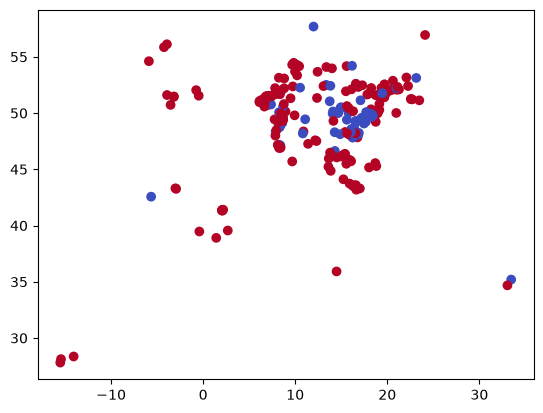

In [31]:
import matplotlib.pyplot as plt
plt.scatter(cities["lon"], cities["lat"], c=cities["return_to_official_only"], cmap="coolwarm")


Villes sans données

In [32]:
trips = pd.read_csv("../data/raw/trips_small.csv", usecols=["city_id"])
cities["has_trips"] = cities["id"].isin(trips["city_id"])
cities[~cities["has_trips"]]


,id,name,lat,lon,timezone,country,return_to_official_only,has_trips
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True,False
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False,False
12,192,Poznań,52.4175,16.93680,Europe/Warsaw,PL,False,False
13,210,Warszawa,52.2354,20.99690,Europe/Warsaw,PL,True,False
14,372,Stacje Sponsorskie Nextbike Veturilo,52.2299,20.99420,Europe/Warsaw,PL,True,False
...,...,...,...,...,...,...,...,...
237,126,Luzern,47.0472,8.30446,Europe/Brussels,CH,True,False
249,789,Palma de Mallorca,39.5602,2.67517,Europe/Brussels,ES,True,False
259,844,El Prat de Llobregat,41.3239,2.09317,Europe/Berlin,ES,True,False
261,851,Sant Joan Despí,41.3680,2.05635,Europe/Berlin,ES,True,False


## Data understanding 
working on the stations.csv file 

In [33]:
stations = pd.read_csv("../data/raw/stations.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

In [34]:
stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [38]:
stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 252.1 KB


In [37]:
stations.isna().sum()

id                  0
city_id             0
name                0
app_number          0
terminal_type     587
place_type          0
bike_racks          0
special_racks       0
rack_locks       2932
lon                 0
lat                 0
dtype: int64

In [46]:
stations.isna().mean() * 100      # rack_locks = 100 %


id                 0.000000
city_id            0.000000
name               0.000000
app_number         0.000000
terminal_type     20.020464
place_type         0.000000
bike_racks         0.000000
special_racks      0.000000
rack_locks       100.000000
lon                0.000000
lat                0.000000
dtype: float64

toutes les valeurs de rack_locks sont missing, il faut supprimer la colone 

In [39]:
stations.describe()

,id,city_id,app_number,place_type,bike_racks,special_racks,rack_locks,lon,lat
count,2.932000e+03,2932.000000,2932.000000,2932.000000,2932.000000,2932.000000,0.0,2932.000000,2932.000000
mean,4.116020e+07,480.171555,29985.929400,3.760914,6.033424,-0.011255,NaN,13.172182,49.272772
std,4.773764e+07,242.781001,61868.290176,6.894175,6.495116,0.486820,NaN,6.914270,4.342509
min,9.400000e+01,7.000000,0.000000,0.000000,0.000000,-10.000000,NaN,-15.758277,7.745476
25%,3.604443e+06,251.000000,4918.750000,0.000000,0.000000,0.000000,NaN,8.156823,47.955417
50%,2.531790e+07,527.000000,7907.500000,0.000000,6.000000,0.000000,NaN,14.314387,50.290478
75%,5.661078e+07,702.000000,48798.250000,0.000000,10.000000,0.000000,NaN,17.488668,51.602447
max,2.192360e+08,858.000000,999574.000000,27.000000,70.000000,12.000000,NaN,33.413632,57.005195


Combien de stations par city ?

In [40]:
stations["city_id"].value_counts()


city_id
251    121
817    121
176     89
680     61
206     60
      ... 
741      2
831      2
647      2
729      1
324      1
Name: count, Length: 185, dtype: int64

In [47]:
print("special_racks < 0 :", (stations["special_racks"] < 0).sum())
stations.loc[stations["special_racks"] < 0, ["id", "name", "bike_racks", "special_racks"]]


special_racks < 0 : 32


,id,name,bike_racks,special_racks
455,19772006,Večgeneracijski center,6,-2
974,21257660,Eurospin Branimirova,6,-2
982,60833931,Matrix Office Park,10,-4
1202,16852569,Kolovare,2,-1
1311,40538270,Poštarska ulica - Pošta,10,-4
1326,3561904,Brulo,20,-10
1329,3562085,Špadići,10,-5
1439,122952272,Levec,6,-2
1440,19772105,Mizarska cesta,6,-2
1441,19772115,Gimnazija Slovenske Konjice,6,-2


=> special_racks négatif pour 32 stations

In [48]:
print("bike_racks == 0 :", (stations["bike_racks"] == 0).sum())
print("bike_racks == 0 et special_racks <= 0 :",
      ((stations["bike_racks"] == 0) & (stations["special_racks"] <= 0)).sum())


bike_racks == 0 : 1220
bike_racks == 0 et special_racks <= 0 : 1219


=>  Stations virtuelles (bike_racks == 0)
Pour appuyer l'idée de « station virtuelle », il faut regarder si ces stations ont quand même des vélos dans stations_status :

In [49]:
status = pd.read_csv("../data/raw/stations_status.csv", usecols=["station_id", "bikes"])
virtual_ids = stations.loc[stations["bike_racks"] == 0, "id"]
status[status["station_id"].isin(virtual_ids)]["bikes"].describe()


count    737206.000000
mean          5.342208
std           7.813015
min           0.000000
25%           2.000000
50%           4.000000
75%           6.000000
max         189.000000
Name: bikes, dtype: float64

In [50]:
m = stations.merge(cities[["id", "name", "lat", "lon"]],
                   left_on="city_id", right_on="id", suffixes=("", "_city"))

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

m["dist_center_km"] = haversine_km(m["lat"], m["lon"], m["lat_city"], m["lon_city"])

print("stations à plus de 50 km :", (m["dist_center_km"] > 50).sum())
m.loc[m["dist_center_km"] > 50, ["name", "name_city", "dist_center_km"]].sort_values("dist_center_km")


stations à plus de 50 km : 42


,name,name_city,dist_center_km
182,Amt Mecklenburgische Kleinseenplatte,MV-Rad,50.709648
210,Bahnhof Mirow,MV-Rad,51.614004
76,Gmünd /WKÖ Bezirksstelle Gmünd,Wachau,59.347644
180,DJH-Jugendherberge Warnemünde 57120 GT,MV-Rad,61.080508
217,DJH-Jugendherberge Warnemünde 57119,MV-Rad,61.080508
202,DJH - Jugendherberge Burg Stargard 57112,MV-Rad,62.207787
215,DJH - Jugendherberge Burg Stargard 57111,MV-Rad,62.207787
181,DJH - Jugendherberge Wismar 57122,MV-Rad,69.241707
201,DJH Jugendherberge Wismar 57121 01,MV-Rad,69.248446
214,DJH - Jugendherberge Stralsund 57109 01,MV-Rad,81.300869


=> Distance au centre de la ville (42 stations à plus de 50 km)

## Data understanding 
working on the stations_status.csv file 

In [41]:
stations_status = pd.read_csv("../data/raw/stations_status.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

In [42]:
stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


In [43]:
stations_status.info()

<class 'pandas.DataFrame'>
RangeIndex: 2925967 entries, 0 to 2925966
Data columns (total 8 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   station_id               int64  
 1   time                     float64
 2   bikes                    int64  
 3   booked_bikes             int64  
 4   bikes_available_to_rent  int64  
 5   free_racks               int64  
 6   free_special_racks       int64  
 7   maintenance              bool   
dtypes: bool(1), float64(1), int64(6)
memory usage: 159.1 MB


In [44]:
stations_status.describe()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks
count,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06
mean,4.084753e+07,1.676531e+09,6.186521e+00,4.599881e-02,6.141577e+00,5.030900e+00,2.216036e+00
std,4.642183e+07,9.488315e+06,6.091899e+00,4.025175e-01,6.099811e+00,5.300172e+00,4.342693e+00
min,9.400000e+01,1.661525e+09,0.000000e+00,-4.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.215911e+06,1.666616e+09,3.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00
50%,1.948980e+07,1.678897e+09,5.000000e+00,0.000000e+00,5.000000e+00,4.000000e+00,0.000000e+00
75%,5.919805e+07,1.685643e+09,8.000000e+00,0.000000e+00,8.000000e+00,8.000000e+00,3.000000e+00
max,2.192360e+08,1.689458e+09,1.890000e+02,3.800000e+01,1.890000e+02,7.000000e+01,3.700000e+01


In [45]:
stations_status.isna().sum()

station_id                 0
time                       0
bikes                      0
booked_bikes               0
bikes_available_to_rent    0
free_racks                 0
free_special_racks         0
maintenance                0
dtype: int64